#Objective

To investigate how product prices, discounts, and promotions are related to FMCG sales.

#Research Questions

1. Is there a relationship between product price and units sold?
2. Do products sell more units during promotional periods?
3. Are larger discounts associated with higher sales?
4. Is there a statistically significant difference between promotional and non-promotional sales?

The findings will help identify potentially useful variables for demand forecasting.


In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
#load the datatset
df = pd.read_csv(
    "../data/fmcg_sales_cleaned.csv",
    parse_dates=["date"]
)

df.shape

(1100000, 33)

In [3]:
# Display all column names
df.columns.tolist()

# Select variables for our analysis
price_promo_df = df[
    ['date', 'sku_id', 'units_sold', 'net_sales', 'discount_pct']
].copy()

price_promo_df.head()

,date,sku_id,units_sold,net_sales,discount_pct
0,2021-01-01,SKU0086,16,151.06,0.1
1,2021-01-02,SKU0086,12,125.88,0.0
2,2021-01-03,SKU0086,38,279.03,0.3
3,2021-01-04,SKU0086,8,83.92,0.0
4,2021-01-05,SKU0086,17,142.66,0.2


In [4]:
# Calculate average units sold at each discount level
discount_sales = (
    price_promo_df.groupby('discount_pct')
    .agg(
        average_units_sold=('units_sold', 'mean'),
        number_of_records=('units_sold', 'count')
    )
    .reset_index()
)
discount_sales

,discount_pct,average_units_sold,number_of_records
0,0.00,55.264665,1011743
1,0.10,94.332046,22274
2,0.15,100.301560,22367
3,0.20,106.695282,22086
4,0.30,116.176266,21530


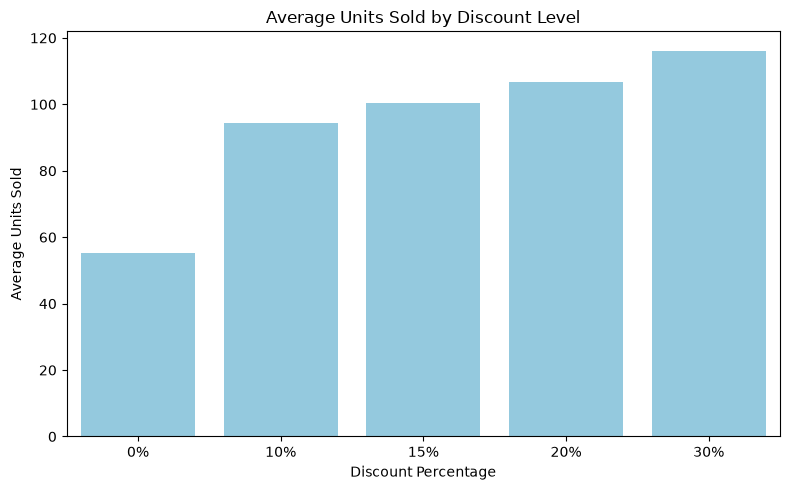

In [5]:
# Convert discount values to percentage labels
discount_sales['discount_label'] = (
    discount_sales['discount_pct'] * 100
).astype(int).astype(str) + '%'

# Plot average units sold by discount level
plt.figure(figsize=(8, 5))

sns.barplot(
    data=discount_sales,
    x='discount_label',
    y='average_units_sold',
    color='skyblue'
)

plt.title('Average Units Sold by Discount Level')
plt.xlabel('Discount Percentage')
plt.ylabel('Average Units Sold')

plt.tight_layout()
plt.show()

The bar chart shows that average units sold increase as discount percentages increase.

Products without discounts sold approximately 55 units per record.
Products with a 30% discount sold approximately 116 units per record.
Higher discount levels were associated with higher average sales.

This means customers may purchase more units when products are discounted.
This is imprtant because discounts may be useful for predicting future product sales and planning promotions.

Discounts are positively associated with units sold in our dataset. However, this does not necessarily mean that discounts cause higher sales.


In [6]:
# Separate sales into discounted and non-discounted groups
discounted_sales = price_promo_df.loc[
    price_promo_df['discount_pct'] > 0,
    'units_sold'
]
non_discounted_sales = price_promo_df.loc[
    price_promo_df['discount_pct'] == 0,
    'units_sold'
]

# Calculate average units sold for each group
print("Average discounted sales:", discounted_sales.mean())
print("Average non-discounted sales:", non_discounted_sales.mean())

Average discounted sales: 104.267582174785
Average non-discounted sales: 55.264665038453444


In [7]:
# Welch's independent-samples t-test
t_stat, p_value = stats.ttest_ind(
    discounted_sales,
    non_discounted_sales,
    equal_var=False
)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6g}")

T-statistic: 195.0426
P-value: 0


 Hypothesis Testing: Discounted vs Non-Discounted Sales

Hypotheses:

H₀: There is no difference in mean units sold between the two groups.
H₁: There is a difference in mean units sold between the two groups.

I chose to use Welch's independent-samples t-test because population standard deviations were unknown and the two groups could have unequal variances. Since our sample sizes were large, the t-distribution closely approximates the normal distribution.

Results:

Average discounted sales: 104.27 units
Average non-discounted sales: 55.26 units
T-statistic: 195.0426
P-value: p < 0.001


This implies that discounted records had higher average units sold than non-discounted records.

The test indicates a statistically significant difference under its assumptions, so we reject the null hypothesis at the 5% significance level.

Conclusion: Discounts are associated with higher average units sold in this dataset. However, this does not prove causation, and repeated observations may affect the reliability of the test's p-value.


In [8]:
# Create a discount indicator
price_promo_df['is_discounted'] = (
    price_promo_df['discount_pct'] > 0
)

# Calculate average units sold for each SKU and discount status
sku_discount_comparison = (
    price_promo_df.groupby(['sku_id', 'is_discounted'])['units_sold']
    .mean()
    .unstack()
)

# Rename columns
sku_discount_comparison = sku_discount_comparison.rename(
    columns={
        False: 'non_discounted_avg',
        True: 'discounted_avg'
    }
)

# Calculate the difference
sku_discount_comparison['difference'] = (
    sku_discount_comparison['discounted_avg']
    - sku_discount_comparison['non_discounted_avg']
)

sku_discount_comparison.head(10)

is_discounted,non_discounted_avg,discounted_avg,difference
sku_id,,,
SKU0001,107.751229,198.563400,90.812171
SKU0002,70.020000,NaN,NaN
SKU0003,23.048037,NaN,NaN
SKU0004,100.360548,NaN,NaN
SKU0005,85.180365,159.963470,74.783105
SKU0006,108.342751,199.115677,90.772926
SKU0007,31.005753,NaN,NaN
SKU0008,25.344475,NaN,NaN
SKU0009,61.345621,NaN,NaN


In [9]:
# Count SKUs with both discounted and non-discounted sales
comparable_skus = sku_discount_comparison.dropna(
    subset=['non_discounted_avg', 'discounted_avg']
)

print("Total SKUs:", len(sku_discount_comparison))
print("Comparable SKUs:", len(comparable_skus))
print(
    "SKUs without both groups:",
    len(sku_discount_comparison) - len(comparable_skus)
)

Total SKUs: 102
Comparable SKUs: 41
SKUs without both groups: 61


In [10]:
# Count products with higher average sales during discounts
higher_sales = (comparable_skus['difference'] > 0).sum()
lower_sales = (comparable_skus['difference'] < 0).sum()
equal_sales = (comparable_skus['difference'] == 0).sum()

print("SKUs with higher discounted sales:", higher_sales)
print("SKUs with lower discounted sales:", lower_sales)
print("SKUs with equal average sales:", equal_sales)

SKUs with higher discounted sales: 41
SKUs with lower discounted sales: 0
SKUs with equal average sales: 0


In [11]:
# Calculate percentage difference in average sales
comparable_skus = comparable_skus.copy()

comparable_skus['percentage_increase'] = (
    (comparable_skus['discounted_avg']
     - comparable_skus['non_discounted_avg'])
    / comparable_skus['non_discounted_avg']
) * 100

# Display summary statistics
comparable_skus['percentage_increase'].describe()

count    41.000000
mean     86.685999
std       2.808309
min      81.704335
25%      84.279475
50%      87.168876
75%      88.460109
max      92.304493
Name: percentage_increase, dtype: float64

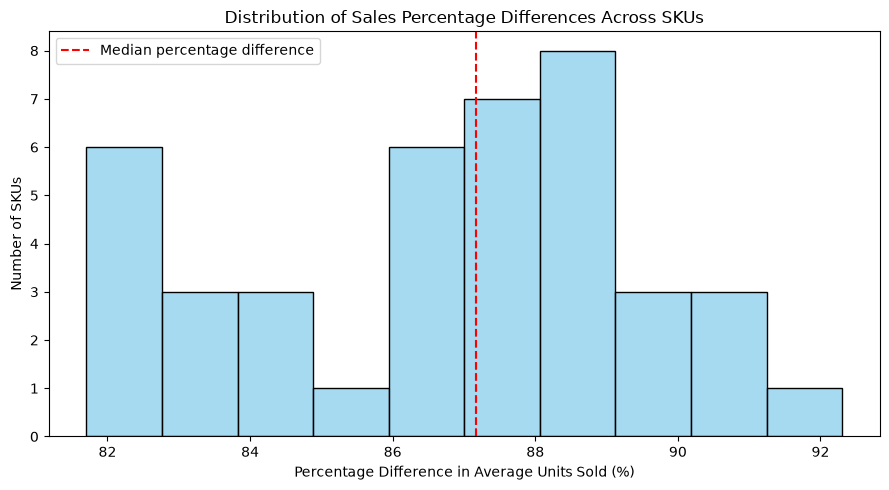

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=comparable_skus,
    x='percentage_increase',
    bins=10,
    color='skyblue',
    edgecolor='black'
)
plt.axvline(
    comparable_skus['percentage_increase'].median(),
    color='red',
    linestyle='--',
    label='Median percentage difference'
)

plt.title('Distribution of Sales Percentage Differences Across SKUs')
plt.xlabel('Percentage Difference in Average Units Sold (%)')
plt.ylabel('Number of SKUs')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
#checking whether some sku's have few discounted observations
sku_discount_counts = (
    price_promo_df
    .groupby(['sku_id', 'is_discounted'])
    .size()
    .unstack(fill_value=0)
)
sku_discount_counts = sku_discount_counts.rename(
    columns={
        False: 'non_discounted_count',
        True: 'discounted_count'
    }
)

sku_discount_counts['discounted_count'].describe()

count     102.000000
mean      865.264706
std      1079.221290
min         0.000000
25%         0.000000
50%         0.000000
75%      2135.250000
max      2847.000000
Name: discounted_count, dtype: float64

In [14]:
# Select discount counts for comparable SKUs
comparable_discount_counts = sku_discount_counts.loc[
    comparable_skus.index
]

# Summarize discounted observation counts
comparable_discount_counts['discounted_count'].describe()

count      41.000000
mean     2152.609756
std       316.992340
min      1314.000000
25%      1971.000000
50%      2190.000000
75%      2409.000000
max      2847.000000
Name: discounted_count, dtype: float64

 SKU-Level Discount Analysis: 

Of the 102 SKUs in the dataset, 41 had both discounted and non-discounted sales observations.

All 41 comparable SKUs recorded higher average units sold during discounted observations.

The mean percentage difference was 86.69%, while the median was 87.17%. Percentage differences ranged from 81.70% to 92.30%.

Each comparable SKU had at least 1,314 discounted observations, with a median of 2,190 discounted records per SKU.

These results suggest a consistent positive association between discounts and sales volume among the comparable products.

However, the findings are descriptive and do not establish that discounts caused higher sales. Seasonal patterns, store differences, and other factors may contribute to the observed relationship. Additionally, 61 SKUs could not be included in the comparison because they lacked observations in both groups.


In [15]:
df.columns.tolist()

['date',
 'year',
 'month',
 'day',
 'weekofyear',
 'weekday',
 'is_weekend',
 'is_holiday',
 'temperature',
 'rain_mm',
 'store_id',
 'country',
 'city',
 'channel',
 'latitude',
 'longitude',
 'sku_id',
 'sku_name',
 'category',
 'subcategory',
 'brand',
 'units_sold',
 'list_price',
 'discount_pct',
 'promo_flag',
 'gross_sales',
 'net_sales',
 'stock_on_hand',
 'stock_out_flag',
 'lead_time_days',
 'supplier_id',
 'purchase_cost',
 'margin_pct']

In [16]:
# Compare promotion status with discount status
promo_discount_table = pd.crosstab(
    df['promo_flag'],
    df['discount_pct'] > 0
)

promo_discount_table

discount_pct,False,True
promo_flag,,
0,1011743,0
1,0,88257


 Relationship Between Promotions and Discounts

A cross-tabulation was used to examine the relationship between `promo_flag` and `discount_pct`.

The results showed that:

1,011,743 records (91.98%) had neither a promotion nor a discount.
88,257 records (8.02%) had both a promotion and a positive discount.
No records had a promotion without a discount or a discount without a promotion.

Therefore, `promo_flag` and the presence of a discount are equivalent indicators in this dataset.

Since promotional and discounted records represent the same observations, a separate promotion-versus-non-promotion comparison would be repetition.


In [17]:
# Summary statistics for product prices
df['list_price'].describe()

count    1.100000e+06
mean     7.712100e+00
std      4.253023e+00
min      1.080000e+00
25%      4.200000e+00
50%      7.380000e+00
75%      1.165000e+01
max      1.480000e+01
Name: list_price, dtype: float64

In [18]:
# Count the number of unique list prices for each SKU
sku_price_variation = (
    df.groupby('sku_id')['list_price']
    .nunique()
)

# Summarize the results
sku_price_variation.describe()

count    102.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: list_price, dtype: float64

In [19]:
# Aggregate price and average units sold by SKU
sku_price_sales = (
    df.groupby('sku_id')
    .agg(
        list_price=('list_price', 'first'),
        average_units_sold=('units_sold', 'mean')
    )
    .reset_index()
)
sku_price_sales.head()

,sku_id,list_price,average_units_sold
0,SKU0001,6.24,125.913664
1,SKU0002,11.25,70.020000
2,SKU0003,3.18,23.048037
3,SKU0004,1.81,100.360548
4,SKU0005,9.42,100.136986


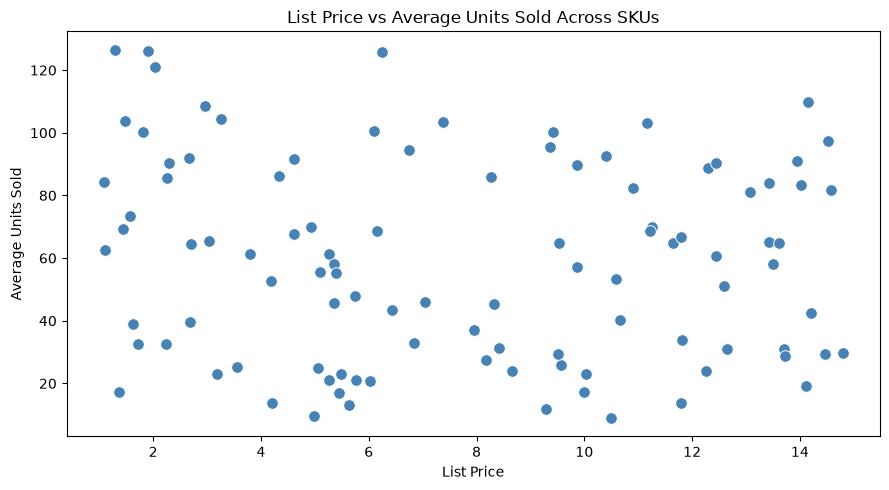

In [20]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=sku_price_sales,
    x='list_price',
    y='average_units_sold',
    color='steelblue',
    s=70
)

plt.title('List Price vs Average Units Sold Across SKUs')
plt.xlabel('List Price')
plt.ylabel('Average Units Sold')
plt.tight_layout()
plt.show()

In [21]:
#calculating the pearson's coefficient of corelation
price_sales_corr = sku_price_sales[
    ['list_price', 'average_units_sold']
].corr(method='pearson')

price_sales_corr

,list_price,average_units_sold
list_price,1.00000,-0.10368
average_units_sold,-0.10368,1.00000


 Relationship Between List Price and Sales Volume

An analysis of the 102 SKUs showed that each product maintained a constant listed price throughout the dataset.

A scatter plot was created to examine the relationship between listed price and average units sold per record across SKUs.

The Pearson correlation coefficient was −0.1037, indicating a very weak negative linear relationship.

The scatter plot showed considerable variation in sales volumes across different price levels, with no clear linear pattern.

Key finding: Listed price alone has a weak linear association with average sales volume across SKUs.

However, this result does not establish how changes in price would affect demand for an individual product, since listed prices remain constant within each SKU.


In [22]:
# Calculate the effective selling price after discounts
price_promo_df['list_price'] = df['list_price']

price_promo_df['effective_price'] = (
    price_promo_df['list_price'] *
    (1 - price_promo_df['discount_pct'])
)

price_promo_df[
    ['sku_id', 'list_price', 'discount_pct', 'effective_price']
].head()

,sku_id,list_price,discount_pct,effective_price
0,SKU0086,10.49,0.1,9.441
1,SKU0086,10.49,0.0,10.490
2,SKU0086,10.49,0.3,7.343
3,SKU0086,10.49,0.0,10.490
4,SKU0086,10.49,0.2,8.392


In [23]:
# Calculate expected gross and net sales
expected_gross_sales = df['units_sold'] * df['list_price']

expected_net_sales = (
    df['units_sold'] * price_promo_df['effective_price']
)

# Compare calculated values with recorded values

print(
    "Gross sales match:",
    np.isclose(df['gross_sales'], expected_gross_sales).mean()
)

print(
    "Net sales match:",
    np.isclose(df['net_sales'], expected_net_sales).mean()
)

Gross sales match: 1.0
Net sales match: 0.9761645454545455


In [24]:
# Identify records where calculated and recorded net sales differ
net_sales_match = np.isclose(
    df['net_sales'],
    expected_net_sales
)

# Select mismatched records
net_sales_mismatches = df.loc[
    ~net_sales_match,
    ['sku_id', 'units_sold', 'list_price', 'discount_pct', 'net_sales']
].copy()

# Add calculated net sales
net_sales_mismatches['expected_net_sales'] = expected_net_sales.loc[
    ~net_sales_match
]

# Calculate the difference
net_sales_mismatches['difference'] = (
    net_sales_mismatches['net_sales'] -
    net_sales_mismatches['expected_net_sales']
)

net_sales_mismatches.head(10)

,sku_id,units_sold,list_price,discount_pct,net_sales,expected_net_sales,difference
0,SKU0086,16,10.49,0.10,151.06,151.0560,0.0040
2,SKU0086,38,10.49,0.30,279.03,279.0340,-0.0040
4,SKU0086,17,10.49,0.20,142.66,142.6640,-0.0040
8,SKU0086,15,10.49,0.15,133.75,133.7475,0.0025
9,SKU0086,17,10.49,0.10,160.50,160.4970,0.0030
18,SKU0086,18,10.49,0.20,151.06,151.0560,0.0040
30,SKU0086,8,10.49,0.10,75.53,75.5280,0.0020
38,SKU0086,9,10.49,0.15,80.25,80.2485,0.0015
43,SKU0086,13,10.49,0.15,115.91,115.9145,-0.0045
44,SKU0086,16,10.49,0.10,151.06,151.0560,0.0040


In [25]:
# Calculate absolute differences across all records
absolute_difference = (
    df['net_sales'] - expected_net_sales
).abs()

# Summarize the differences
absolute_difference.describe()

count    1.100000e+06
mean     1.773355e-04
std      7.664113e-04
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.421085e-14
max      5.000000e-03
dtype: float64

In [26]:
# Check whether calculated and recorded net sales
# agree within half a cent
np.isclose(
    df['net_sales'],
    expected_net_sales,
    atol=0.0051,
    rtol=0
).mean()

np.float64(1.0)

In [27]:
# Select only SKUs with both discounted and non-discounted sales
valid_sku_ids = comparable_skus.index

price_variation_df = price_promo_df[
    price_promo_df['sku_id'].isin(valid_sku_ids)
].copy()

# Calculate price-sales correlations for these SKUs

valid_price_correlations = (
    price_variation_df.groupby('sku_id')
    .apply(
        lambda group: group['effective_price'].corr(group['units_sold']),
        include_groups=False
    )
)

valid_price_correlations.describe()

count    41.000000
mean     -0.561571
std       0.030361
min      -0.618800
25%      -0.582781
50%      -0.563344
75%      -0.541021
max      -0.502849
dtype: float64

 Relationship Between Effective Selling Price and Demand

The relationship between effective selling price and units sold was examined separately for SKUs with both discounted and non-discounted observations.

Of the 102 SKUs, 41 had sufficient price variation** for this analysis.

All 41 SKUs showed negative Pearson correlation coefficients, ranging from −0.6188 to −0.5028.

The mean correlation was −0.5616, indicating a moderate negative linear association between effective selling price and units sold.

This suggests that lower effective selling prices were generally associated with higher sales volumes within these products.

However, because effective price variation results from discounts, these findings largely reflect the previously observed discount–sales relationship. They should not be interpreted as evidence of a causal effect of price changes on demand.
